# 🔥 PyTorch & TensorFlow Basics — Complete Tutorial

Welcome! This notebook teaches you the fundamentals of both **PyTorch** and **TensorFlow/Keras** side by side.

### 📚 What You'll Learn
| Topic | PyTorch | TensorFlow/Keras |
|-------|---------|------------------|
| Tensors & Arrays | `torch.Tensor` | `tf.Tensor` |
| Autograd / Gradients | `torch.autograd` | `tf.GradientTape` |
| Building Models | `nn.Module` | `keras.Sequential` |
| Training Loop | Manual loop | `.fit()` API |
| Save & Load | `torch.save` | `model.save` |

### 🗂️ Notebook Structure
1. Installation & Setup
2. Tensors — the building blocks
3. Tensor Operations & Math
4. Autograd (Automatic Differentiation)
5. Building Neural Networks
6. Training on Real Data
7. Evaluation & Metrics
8. Saving & Loading Models
9. ✅ Practice Tasks (with solutions)

> **Tip:** Run each cell top-to-bottom using `Shift+Enter`.

---
## 1. 📦 Installation & Setup

In [1]:
# Install required libraries (run once)
!pip install torch torchvision torchaudio --quiet
!pip install tensorflow --quiet
!pip install matplotlib numpy scikit-learn --quiet
print("✅ All packages installed!")

✅ All packages installed!


In [2]:
# ── Core imports ──────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Version check
print(f"PyTorch version   : {torch.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available (PyTorch): {torch.cuda.is_available()}")
print(f"GPU available (TF)     : {len(tf.config.list_physical_devices('GPU')) > 0}")

PyTorch version   : 2.14.1+cpu
TensorFlow version: 2.21.0
GPU available (PyTorch): False
GPU available (TF)     : False


---
## 2. 🧱 Tensors — The Building Blocks

A **tensor** is a multi-dimensional array — the fundamental data structure in both frameworks.

| Dimensions | Name | Example shape |
|-----------|------|---------------|
| 0-D | Scalar | `()` |
| 1-D | Vector | `(3,)` |
| 2-D | Matrix | `(3, 4)` |
| 3-D | Tensor | `(2, 3, 4)` |

In [3]:
# ════════════════════════════════════
#  PyTorch — Creating Tensors
# ════════════════════════════════════

# From Python lists
pt_scalar = torch.tensor(42.0)
pt_vector = torch.tensor([1.0, 2.0, 3.0])
pt_matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])

# Special tensors
pt_zeros   = torch.zeros(3, 4)       # all zeros
pt_ones    = torch.ones(2, 3)        # all ones
pt_rand    = torch.rand(2, 3)        # uniform [0, 1)
pt_randn   = torch.randn(2, 3)       # standard normal N(0,1)
pt_eye     = torch.eye(3)            # identity matrix
pt_arange  = torch.arange(0, 10, 2) # like range()

print("── PyTorch Tensors ──")
print(f"Scalar : {pt_scalar}  | shape: {pt_scalar.shape}")
print(f"Vector : {pt_vector}  | shape: {pt_vector.shape}")
print(f"Matrix shape: {pt_matrix.shape}")
print(f"Zeros :\n{pt_zeros}")
print(f"Random (uniform):\n{pt_rand.numpy().round(3)}")
print(f"Arange: {pt_arange}")

── PyTorch Tensors ──
Scalar : 42.0  | shape: torch.Size([])
Vector : tensor([1., 2., 3.])  | shape: torch.Size([3])
Matrix shape: torch.Size([3, 2])
Zeros :
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
Random (uniform):
[[0.22  0.796 0.296]
 [0.505 0.481 0.158]]
Arange: tensor([0, 2, 4, 6, 8])


In [4]:
# ════════════════════════════════════
#  TensorFlow — Creating Tensors
# ════════════════════════════════════

# From Python lists
tf_scalar = tf.constant(42.0)
tf_vector = tf.constant([1.0, 2.0, 3.0])
tf_matrix = tf.constant([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])

# Special tensors
tf_zeros  = tf.zeros([3, 4])
tf_ones   = tf.ones([2, 3])
tf_rand   = tf.random.uniform([2, 3])
tf_randn  = tf.random.normal([2, 3])
tf_eye    = tf.eye(3)
tf_range  = tf.range(0, 10, 2)

print("── TensorFlow Tensors ──")
print(f"Scalar : {tf_scalar.numpy()}  | shape: {tf_scalar.shape}")
print(f"Vector : {tf_vector.numpy()}  | shape: {tf_vector.shape}")
print(f"Matrix shape: {tf_matrix.shape}")
print(f"Random (uniform):\n{tf_rand.numpy().round(3)}")
print(f"Range: {tf_range.numpy()}")

── TensorFlow Tensors ──
Scalar : 42.0  | shape: ()
Vector : [1. 2. 3.]  | shape: (3,)
Matrix shape: (3, 2)
Random (uniform):
[[0.565 0.11  0.371]
 [0.567 0.386 0.128]]
Range: [0 2 4 6 8]


In [5]:
# ── Indexing & Slicing (same in both!) ─────────────────────────
t = torch.tensor([[10, 20, 30],
                   [40, 50, 60],
                   [70, 80, 90]])

print("Full tensor:\n", t.numpy())
print("Row 0     :", t[0].numpy())          # first row
print("Col 1     :", t[:, 1].numpy())       # second column
print("Element[1,2]:", t[1, 2].item())      # scalar value
print("Sub-matrix  :\n", t[0:2, 1:3].numpy())  # slice

# Reshape
flat   = t.reshape(-1)         # flatten to 1D
reshaped = t.reshape(1, 9)     # shape (1, 9)
print("Flattened :", flat.numpy())
print("Reshaped  :", reshaped.numpy())

Full tensor:
 [[10 20 30]
 [40 50 60]
 [70 80 90]]
Row 0     : [10 20 30]
Col 1     : [20 50 80]
Element[1,2]: 60
Sub-matrix  :
 [[20 30]
 [50 60]]
Flattened : [10 20 30 40 50 60 70 80 90]
Reshaped  : [[10 20 30 40 50 60 70 80 90]]


---
## 3. ➕ Tensor Operations & Math

All the standard mathematical operations are available element-wise or as matrix operations.

In [6]:
# ════════════════════════════════════
#  PyTorch — Operations
# ════════════════════════════════════
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])

print("── Element-wise Arithmetic ──")
print("a + b =", (a + b).numpy())
print("a - b =", (a - b).numpy())
print("a * b =", (a * b).numpy())      # element-wise multiply
print("a / b =", (a / b).numpy())
print("a ** 2 =", (a ** 2).numpy())    # power

print("\n── Reduction Operations ──")
print("sum :", a.sum().item())
print("mean:", a.mean().item())
print("max :", a.max().item())
print("min :", a.min().item())
print("std :", a.std().item())

print("\n── Matrix Multiplication ──")
A = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
B = torch.tensor([[5.0, 6.0], [7.0, 8.0]])
print("A @ B =\n", (A @ B).numpy())          # matrix multiply
print("dot product a·b =", torch.dot(a, b).item())

print("\n── Math Functions ──")
print("sqrt(a)  =", torch.sqrt(a).numpy())
print("exp(a)   =", torch.exp(a).numpy().round(3))
print("log(a)   =", torch.log(a).numpy().round(3))
print("abs(-a)  =", torch.abs(-a).numpy())

── Element-wise Arithmetic ──
a + b = [5. 7. 9.]
a - b = [-3. -3. -3.]
a * b = [ 4. 10. 18.]
a / b = [0.25 0.4  0.5 ]
a ** 2 = [1. 4. 9.]

── Reduction Operations ──
sum : 6.0
mean: 2.0
max : 3.0
min : 1.0
std : 1.0

── Matrix Multiplication ──
A @ B =
 [[19. 22.]
 [43. 50.]]
dot product a·b = 32.0

── Math Functions ──
sqrt(a)  = [1.        1.4142135 1.7320508]
exp(a)   = [ 2.718  7.389 20.086]
log(a)   = [0.    0.693 1.099]
abs(-a)  = [1. 2. 3.]


In [7]:
# ════════════════════════════════════
#  TensorFlow — Operations
# ════════════════════════════════════
a_tf = tf.constant([1.0, 2.0, 3.0])
b_tf = tf.constant([4.0, 5.0, 6.0])

print("── Element-wise Arithmetic ──")
print("a + b =", tf.add(a_tf, b_tf).numpy())
print("a * b =", tf.multiply(a_tf, b_tf).numpy())
print("a ** 2 =", tf.pow(a_tf, 2).numpy())

print("\n── Reduction Operations ──")
print("sum :", tf.reduce_sum(a_tf).numpy())
print("mean:", tf.reduce_mean(a_tf).numpy())
print("max :", tf.reduce_max(a_tf).numpy())

print("\n── Matrix Multiplication ──")
A_tf = tf.constant([[1.0, 2.0], [3.0, 4.0]])
B_tf = tf.constant([[5.0, 6.0], [7.0, 8.0]])
print("A @ B =\n", tf.matmul(A_tf, B_tf).numpy())

print("\n── Math Functions ──")
print("sqrt(a) =", tf.sqrt(a_tf).numpy())
print("exp(a)  =", tf.exp(a_tf).numpy().round(3))
print("log(a)  =", tf.math.log(a_tf).numpy().round(3))

── Element-wise Arithmetic ──
a + b = [5. 7. 9.]
a * b = [ 4. 10. 18.]
a ** 2 = [1. 4. 9.]

── Reduction Operations ──
sum : 6.0
mean: 2.0
max : 3.0

── Matrix Multiplication ──
A @ B =
 [[19. 22.]
 [43. 50.]]

── Math Functions ──
sqrt(a) = [1.        1.4142135 1.7320508]
exp(a)  = [ 2.718  7.389 20.086]
log(a)  = [0.    0.693 1.099]


---
## 4. 🔄 Autograd — Automatic Differentiation

Autograd computes **gradients automatically**, which is the core of training neural networks via backpropagation.

Given a function `L = f(x)`, autograd computes `dL/dx` for you.

In [8]:
# ════════════════════════════════════
#  PyTorch — Autograd
# ════════════════════════════════════

# requires_grad=True tells PyTorch to track operations for this tensor
x = torch.tensor(3.0, requires_grad=True)

# Define a function:  y = x^2 + 2x + 1
y = x**2 + 2*x + 1
print(f"x = {x.item()},  y = {y.item()}")

# Compute gradient: dy/dx = 2x + 2
y.backward()                          # trigger backprop
print(f"dy/dx = {x.grad.item()}")     # should be 2(3)+2 = 8
print(f"Manual check: 2*{x.item()}+2 = {2*x.item()+2}")

print("\n── Multi-variable gradients ──")
# z = 3a^2 + ab  →  dz/da = 6a + b,  dz/db = a
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(5.0, requires_grad=True)
z = 3 * a**2 + a * b
z.backward()
print(f"dz/da = {a.grad.item()} (expected {6*2 + 5})")
print(f"dz/db = {b.grad.item()} (expected {2})")

x = 3.0,  y = 16.0
dy/dx = 8.0
Manual check: 2*3.0+2 = 8.0

── Multi-variable gradients ──
dz/da = 17.0 (expected 17)
dz/db = 2.0 (expected 2)


In [9]:
# ════════════════════════════════════
#  TensorFlow — GradientTape
# ════════════════════════════════════

# tf.Variable is tracked automatically inside a GradientTape
x = tf.Variable(3.0)

with tf.GradientTape() as tape:
    y = x**2 + 2*x + 1

dy_dx = tape.gradient(y, x)
print(f"x = {x.numpy()},  y = {y.numpy()}")
print(f"dy/dx = {dy_dx.numpy()}  (expected 8)")

print("\n── Multi-variable gradients ──")
a = tf.Variable(2.0)
b = tf.Variable(5.0)
with tf.GradientTape() as tape:
    z = 3 * a**2 + a * b
grads = tape.gradient(z, [a, b])
print(f"dz/da = {grads[0].numpy()} (expected {6*2+5})")
print(f"dz/db = {grads[1].numpy()} (expected 2)")

x = 3.0,  y = 16.0
dy/dx = 8.0  (expected 8)

── Multi-variable gradients ──
dz/da = 17.0 (expected 17)
dz/db = 2.0 (expected 2)


---
## 5. 🧠 Building Neural Networks

A neural network is a stack of **layers**, each performing a linear transformation followed by a non-linear **activation function**.

```
Input → [Linear → Activation] × N → Output
```

Common activation functions: **ReLU**, **Sigmoid**, **Tanh**, **Softmax**

In [10]:
# ════════════════════════════════════
#  PyTorch — Building a Model with nn.Module
# ════════════════════════════════════

class SimpleNet(nn.Module):
    """
    A fully-connected network:
      Input(8) → Hidden(16) → Hidden(8) → Output(1)
    """
    def __init__(self):
        super().__init__()
        # Define layers
        self.net = nn.Sequential(
            nn.Linear(8, 16),   # input: 8 features → 16 neurons
            nn.ReLU(),
            nn.Linear(16, 8),   # 16 → 8
            nn.ReLU(),
            nn.Linear(8, 1),    # 8 → 1 output
            nn.Sigmoid()        # output in [0,1] for binary classification
        )

    def forward(self, x):
        return self.net(x)

pt_model = SimpleNet()
print("── PyTorch Model Architecture ──")
print(pt_model)

# Count parameters
total_params = sum(p.numel() for p in pt_model.parameters())
trainable    = sum(p.numel() for p in pt_model.parameters() if p.requires_grad)
print(f"\nTotal parameters    : {total_params:,}")
print(f"Trainable parameters: {trainable:,}")

# Test forward pass
dummy_input = torch.randn(4, 8)   # batch of 4 samples, each with 8 features
output = pt_model(dummy_input)
print(f"\nInput  shape: {dummy_input.shape}")
print(f"Output shape: {output.shape}")
print(f"Output values: {output.detach().numpy().flatten().round(4)}")

── PyTorch Model Architecture ──
SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)

Total parameters    : 289
Trainable parameters: 289

Input  shape: torch.Size([4, 8])
Output shape: torch.Size([4, 1])
Output values: [0.3755 0.3847 0.4146 0.3569]


In [18]:
# ════════════════════════════════════
#  TensorFlow — Building a Model with Keras
# ════════════════════════════════════

tf_model = tf.keras.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8,  activation='relu'),
    layers.Dense(1,  activation='sigmoid')
], name="SimpleNet")

print("── TensorFlow Model Architecture ──")
tf_model.summary()

# Test forward pass
dummy_tf = tf.random.normal([4, 8])
tf_out   = tf_model(dummy_tf)
print(f"\nOutput shape : {tf_out.shape}")
print(f"Output values: {tf_out.numpy().flatten().round(4)}")

── TensorFlow Model Architecture ──


Model: "SimpleNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)


Output shape : (4, 1)
Output values: [0.3847 0.3659 0.438  0.7772]


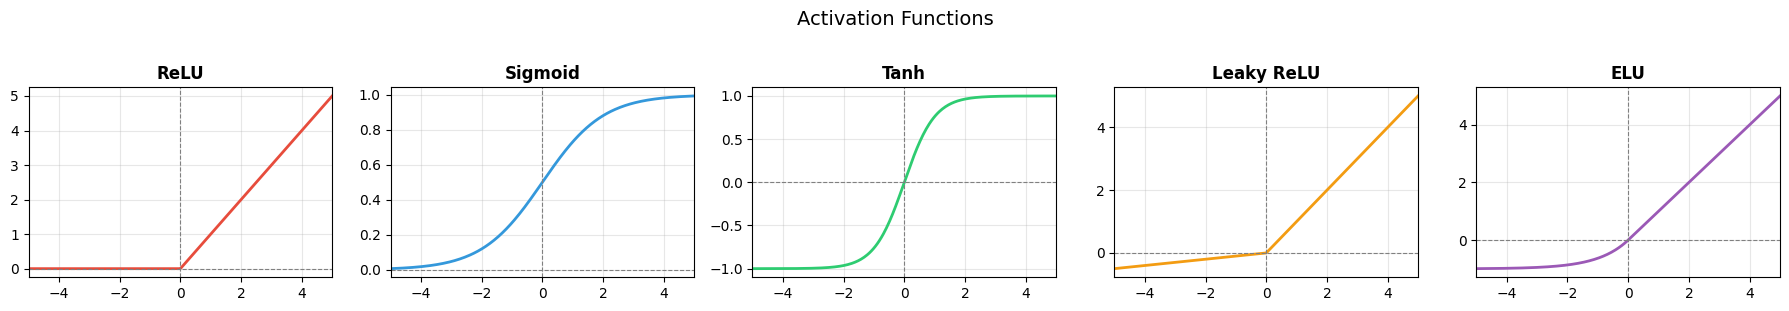

In [19]:
# ── Visualising Activation Functions ───────────────────────────
x_plot = np.linspace(-5, 5, 300)
x_t    = torch.tensor(x_plot, dtype=torch.float32)

activations = {
    'ReLU'    : torch.relu(x_t),
    'Sigmoid' : torch.sigmoid(x_t),
    'Tanh'    : torch.tanh(x_t),
    'Leaky ReLU': nn.functional.leaky_relu(x_t, 0.1),
    'ELU'     : nn.functional.elu(x_t),
}

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
for ax, (name, val), color in zip(axes, activations.items(), colors):
    ax.plot(x_plot, val.numpy(), color=color, lw=2)
    ax.axhline(0, color='gray', lw=0.8, ls='--')
    ax.axvline(0, color='gray', lw=0.8, ls='--')
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlim(-5, 5)
    ax.grid(alpha=0.3)
plt.suptitle('Activation Functions', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
## 6. 🚀 Training on Real Data

We'll train on the **Breast Cancer dataset** (binary classification) — predict malignant (1) vs benign (0).

### Training Loop Steps:
1. **Forward pass**: compute predictions
2. **Compute loss**: measure how wrong predictions are
3. **Backward pass**: compute gradients
4. **Update weights**: apply optimizer step
5. **Zero gradients** (PyTorch only): prevent accumulation

In [21]:
# ── Data Preparation (shared by both frameworks) ───────────────
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data   = load_breast_cancer()
X, y   = data.data, data.target.astype(np.float32)

# Split into train / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalize: mean=0, std=1
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test  = scaler.transform(X_test).astype(np.float32)

# print(f"Dataset   : {data.dataset_name}")
print(f"Features  : {X.shape[1]}")
print(f"Train size: {X_train.shape[0]}")
print(f"Test size : {X_test.shape[0]}")
print(f"Classes   : {dict(zip(data.target_names, np.bincount(data.target)))}")

Features  : 30
Train size: 455
Test size : 114
Classes   : {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


In [22]:
# ════════════════════════════════════
#  PyTorch — Full Training Loop
# ════════════════════════════════════

# 1. Convert data to tensors
X_tr_pt = torch.tensor(X_train)
y_tr_pt = torch.tensor(y_train).unsqueeze(1)   # shape (N, 1)
X_te_pt = torch.tensor(X_test)
y_te_pt = torch.tensor(y_test).unsqueeze(1)

# 2. DataLoader (batching + shuffling)
train_ds = TensorDataset(X_tr_pt, y_tr_pt)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)

# 3. Build model
class CancerNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x)

pt_cancer_model = CancerNet(X_train.shape[1])

# 4. Loss & Optimizer
criterion = nn.BCELoss()                              # Binary Cross Entropy
optimizer = optim.Adam(pt_cancer_model.parameters(), lr=1e-3)

# 5. Training Loop
EPOCHS = 50
pt_train_losses, pt_val_accs = [], []

for epoch in range(EPOCHS):
    pt_cancer_model.train()
    epoch_loss = 0.0

    for X_batch, y_batch in train_dl:
        optimizer.zero_grad()              # ① zero gradients
        preds = pt_cancer_model(X_batch)   # ② forward pass
        loss  = criterion(preds, y_batch)  # ③ compute loss
        loss.backward()                    # ④ backward pass
        optimizer.step()                   # ⑤ update weights
        epoch_loss += loss.item()

    # Validation accuracy
    pt_cancer_model.eval()
    with torch.no_grad():
        val_preds = pt_cancer_model(X_te_pt)
        val_acc   = ((val_preds > 0.5).float() == y_te_pt).float().mean().item()

    avg_loss = epoch_loss / len(train_dl)
    pt_train_losses.append(avg_loss)
    pt_val_accs.append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Loss: {avg_loss:.4f} | Val Acc: {val_acc:.4f}")

print(f"\n✅ Final PyTorch Test Accuracy: {pt_val_accs[-1]:.4f}")

Epoch  10/50 | Loss: 0.1087 | Val Acc: 0.9825
Epoch  20/50 | Loss: 0.0553 | Val Acc: 0.9912
Epoch  30/50 | Loss: 0.0433 | Val Acc: 0.9912
Epoch  40/50 | Loss: 0.0421 | Val Acc: 0.9825
Epoch  50/50 | Loss: 0.0271 | Val Acc: 0.9825

✅ Final PyTorch Test Accuracy: 0.9825


In [23]:
# ════════════════════════════════════
#  TensorFlow — Training with .fit()
# ════════════════════════════════════

# Build model
tf_cancer_model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1,  activation='sigmoid')
], name="CancerNet")

# Compile: specify loss, optimizer, metrics
tf_cancer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train using the elegant .fit() API
tf_history = tf_cancer_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=0       # set to 1 to see per-epoch output
)

# Evaluate
tf_loss, tf_acc = tf_cancer_model.evaluate(X_test, y_test, verbose=0)
print(f"✅ Final TensorFlow Test Accuracy: {tf_acc:.4f}")
print(f"   TensorFlow Test Loss          : {tf_loss:.4f}")

✅ Final TensorFlow Test Accuracy: 0.9825
   TensorFlow Test Loss          : 0.0567


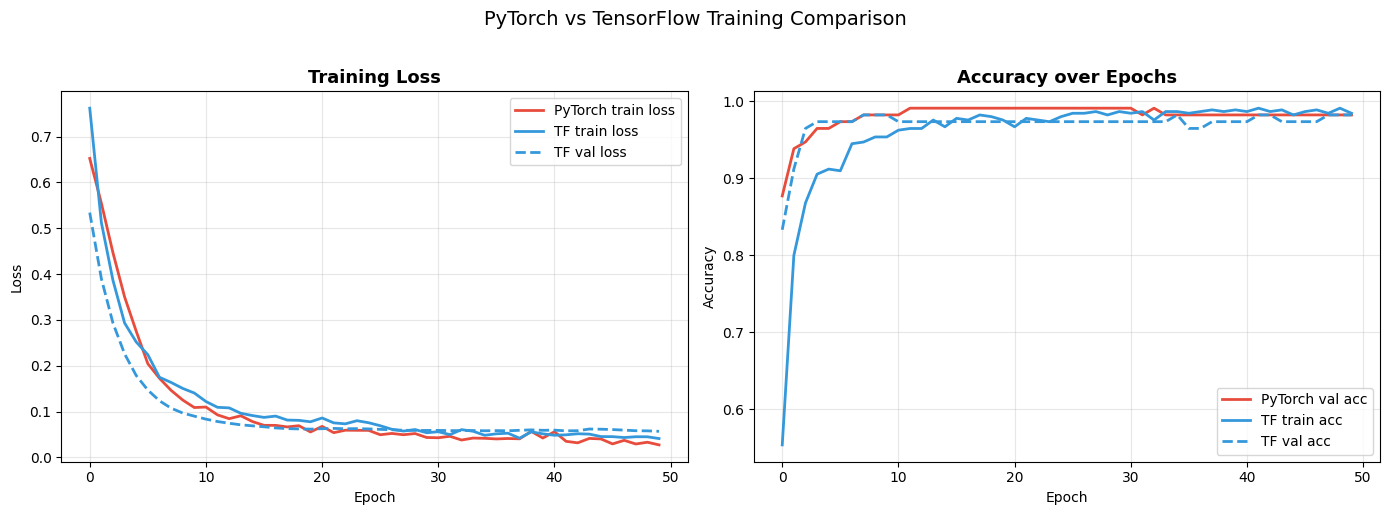

In [24]:
# ── Visualise Training Curves ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax = axes[0]
ax.plot(pt_train_losses, label='PyTorch train loss',  color='#e74c3c', lw=2)
ax.plot(tf_history.history['loss'],     label='TF train loss',     color='#3498db', lw=2)
ax.plot(tf_history.history['val_loss'], label='TF val loss',       color='#3498db', lw=2, ls='--')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.set_title('Training Loss', fontsize=13, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)

# Accuracy curves
ax = axes[1]
ax.plot(pt_val_accs,                         label='PyTorch val acc',    color='#e74c3c', lw=2)
ax.plot(tf_history.history['accuracy'],      label='TF train acc',       color='#3498db', lw=2)
ax.plot(tf_history.history['val_accuracy'],  label='TF val acc',         color='#3498db', lw=2, ls='--')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.set_title('Accuracy over Epochs', fontsize=13, fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)

plt.suptitle('PyTorch vs TensorFlow Training Comparison', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
## 7. 📊 Evaluation & Metrics

After training, we evaluate the model's performance using metrics beyond simple accuracy.

In [25]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

# ── PyTorch predictions ─────────────────────────────────────────
pt_cancer_model.eval()
with torch.no_grad():
    pt_probs = pt_cancer_model(X_te_pt).numpy().flatten()
pt_preds = (pt_probs > 0.5).astype(int)

# ── TensorFlow predictions ──────────────────────────────────────
tf_probs = tf_cancer_model.predict(X_test, verbose=0).flatten()
tf_preds = (tf_probs > 0.5).astype(int)

# ── Classification Report ──────────────────────────────────────
print("═══ PyTorch Classification Report ═══")
print(classification_report(y_test, pt_preds,
                             target_names=['Benign', 'Malignant']))

print("═══ TensorFlow Classification Report ═══")
print(classification_report(y_test, tf_preds,
                             target_names=['Benign', 'Malignant']))

═══ PyTorch Classification Report ═══
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98        43
   Malignant       0.99      0.99      0.99        71

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

═══ TensorFlow Classification Report ═══
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98        43
   Malignant       0.99      0.99      0.99        71

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



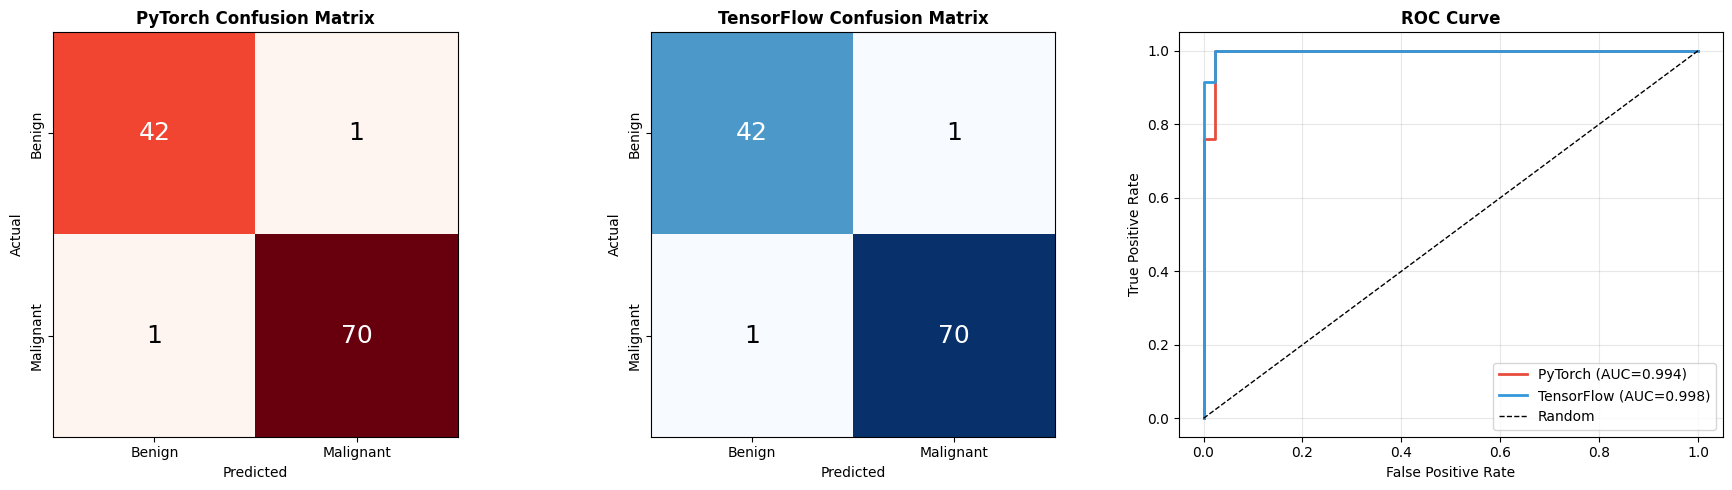

In [26]:
# ── Confusion Matrix + ROC Curve ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrices
for ax, preds, title, color in zip(
    axes[:2],
    [pt_preds, tf_preds],
    ['PyTorch', 'TensorFlow'],
    ['Reds', 'Blues']
):
    cm = confusion_matrix(y_test, preds)
    im = ax.imshow(cm, cmap=color)
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Benign','Malignant'])
    ax.set_yticklabels(['Benign','Malignant'], rotation=90, va='center')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'{title} Confusion Matrix', fontweight='bold')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i,j], ha='center', va='center',
                    fontsize=18, color='white' if cm[i,j] > cm.max()/2 else 'black')

# ROC Curve
ax = axes[2]
for probs, label, color in [
    (pt_probs, 'PyTorch', '#e74c3c'),
    (tf_probs, 'TensorFlow', '#3498db')
]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{label} (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 8. 💾 Saving & Loading Models

In [27]:
import os
os.makedirs('saved_models', exist_ok=True)

# ════════════════════════════════════
#  PyTorch — Save & Load
# ════════════════════════════════════

# Option A: Save only the weights (recommended)
torch.save(pt_cancer_model.state_dict(), 'saved_models/pt_model_weights.pth')
print("✅ PyTorch weights saved.")

# Load: recreate model, then load weights
loaded_pt = CancerNet(X_train.shape[1])
loaded_pt.load_state_dict(torch.load('saved_models/pt_model_weights.pth'))
loaded_pt.eval()

# Verify
with torch.no_grad():
    reloaded_pred = (loaded_pt(X_te_pt) > 0.5).float()
    reloaded_acc  = (reloaded_pred == y_te_pt).float().mean().item()
print(f"Reloaded PyTorch Accuracy: {reloaded_acc:.4f}\n")

# ════════════════════════════════════
#  TensorFlow — Save & Load
# ════════════════════════════════════

# Option A: Save full model (architecture + weights + optimizer)
tf_cancer_model.save('saved_models/tf_model.keras')
print("✅ TensorFlow full model saved.")

# Load
loaded_tf  = keras.models.load_model('saved_models/tf_model.keras')
tf_reload_loss, tf_reload_acc = loaded_tf.evaluate(X_test, y_test, verbose=0)
print(f"Reloaded TensorFlow Accuracy: {tf_reload_acc:.4f}")

✅ PyTorch weights saved.
Reloaded PyTorch Accuracy: 0.9825

✅ TensorFlow full model saved.
Reloaded TensorFlow Accuracy: 0.9825


---
## 9. ✅ Practice Tasks

Work through these tasks to solidify your understanding. Each task has a **description**, a **starter cell**, and a **solution cell** (hidden until you try!).

> 💡 **Tip**: Try to solve each task yourself before looking at the solution.

### 🎯 Task 1 — Tensor Operations
Create a 4×4 matrix of random integers between 0 and 9 using PyTorch.  
Then: (a) print its shape and dtype, (b) compute row-wise mean, (c) find the index of the maximum element.

In [28]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: use torch.randint(low, high, size)

# TODO: create 4x4 integer tensor
torch.manual_seed(42)

matrix = torch.randint(0, 10, (4, 4))

print("Matrix:")
print(matrix)

# TODO: print shape and dtype
print("\nShape:", matrix.shape)
print("Data type:", matrix.dtype)

# TODO: compute row-wise mean
row_mean = matrix.float().mean(dim=1)

print("\nRow-wise Mean:")
print(row_mean)

# TODO: find index of global max
max_value = matrix.max()
max_index = matrix.argmax().item()

row, col = divmod(max_index, matrix.shape[1])

print("\nMaximum Value:", max_value.item())
print("Maximum Position:", (row, col))

Matrix:
tensor([[2, 7, 6, 4],
        [6, 5, 0, 4],
        [0, 3, 8, 4],
        [0, 4, 1, 2]])

Shape: torch.Size([4, 4])
Data type: torch.int64

Row-wise Mean:
tensor([4.7500, 3.7500, 3.7500, 1.7500])

Maximum Value: 8
Maximum Position: (2, 2)


In [29]:
# ── ✅ Task 1 Solution ─────────────────────────────────────────

# (a) Create tensor
mat = torch.randint(0, 10, (4, 4))
print("Matrix:\n", mat.numpy())
print("Shape:", mat.shape, "| dtype:", mat.dtype)

# (b) Row-wise mean (need float for mean)
row_means = mat.float().mean(dim=1)
print("Row-wise means:", row_means.numpy().round(2))

# (c) Index of global max
flat_idx = mat.argmax().item()
row, col  = divmod(flat_idx, 4)
print(f"Max value {mat.max().item()} at position ({row}, {col})")

Matrix:
 [[5 5 7 6]
 [9 6 3 1]
 [9 3 1 9]
 [7 9 2 0]]
Shape: torch.Size([4, 4]) | dtype: torch.int64
Row-wise means: [5.75 4.75 5.5  4.5 ]
Max value 9 at position (1, 0)


### 🎯 Task 2 — Gradient Computation
Using PyTorch autograd, define `f(x) = sin(x²) + cos(x)`.  
Compute and print `df/dx` at `x = π/4`. Then verify numerically using finite differences.

In [30]:
# ── Your Solution ──────────────────────────────────────────────
import math

# TODO: define x = π/4 with requires_grad
# TODO: compute f(x) = sin(x²) + cos(x)
# TODO: call .backward() and print gradient
# TODO: verify with finite differences: [f(x+h) - f(x-h)] / (2h)

# Define x
x = torch.tensor(
    math.pi / 4,
    dtype=torch.float64,
    requires_grad=True
)

# Define function
f = torch.sin(x**2) + torch.cos(x)

# Automatic differentiation
f.backward()

autograd_gradient = x.grad.item()

print("Function Value:", f.item())
print("Autograd Gradient:", autograd_gradient)

# Numerical verification using finite differences
h = 1e-5

def function(x):
    return torch.sin(x**2) + torch.cos(x)

x_value = torch.tensor(
    math.pi / 4,
    dtype=torch.float64
)

numerical_gradient = (
    function(x_value + h) -
    function(x_value - h)
) / (2 * h)

print("Numerical Gradient:", numerical_gradient.item())

print(
    "Absolute Difference:",
    abs(autograd_gradient - numerical_gradient.item())
)

Function Value: 1.2855755705411056
Autograd Gradient: 0.5741988785299474
Numerical Gradient: 0.574198878389165
Absolute Difference: 1.4078249677140775e-10


### 🎯 Task 3 — Build a Regression Network (PyTorch)
Build and train a PyTorch model to **predict Boston-style housing prices** on the California Housing dataset.  
Use `MSELoss`, `Adam` optimizer, and plot the training loss curve.

Epoch 10/100, Loss: 0.3608
Epoch 20/100, Loss: 0.3147
Epoch 30/100, Loss: 0.2941
Epoch 40/100, Loss: 0.2787
Epoch 50/100, Loss: 0.2737
Epoch 60/100, Loss: 0.2642
Epoch 70/100, Loss: 0.2596
Epoch 80/100, Loss: 0.2563
Epoch 90/100, Loss: 0.2545
Epoch 100/100, Loss: 0.2534

Test MSE: 0.2719818651676178
Test R2: 0.7924450635910034


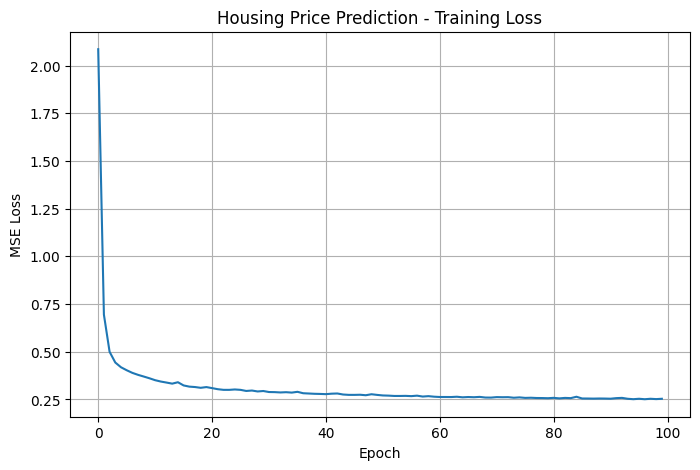

In [32]:
# ── Your Solution ──────────────────────────────────────────────
from sklearn.datasets import fetch_california_housing

# Data loading hint:
# housing = fetch_california_housing()
# X_h, y_h = housing.data.astype(np.float32), housing.target.astype(np.float32)

# TODO: Load & split & scale data
# TODO: Build nn.Module with Linear layers (8 → 64 → 32 → 1)
# TODO: Train for 100 epochs with MSELoss + Adam
# TODO: Plot loss curve

# Load California Housing dataset
housing = fetch_california_housing()

X_h = housing.data.astype(np.float32)
y_h = housing.target.astype(np.float32)

# Split data
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_h, y_h,
    test_size=0.2,
    random_state=42
)

# Standardize features
housing_scaler = StandardScaler()

X_h_train = housing_scaler.fit_transform(
    X_h_train
).astype(np.float32)

X_h_test = housing_scaler.transform(
    X_h_test
).astype(np.float32)

# Convert to PyTorch tensors
X_train_pt = torch.tensor(X_h_train)
y_train_pt = torch.tensor(y_h_train).view(-1, 1)

X_test_pt = torch.tensor(X_h_test)
y_test_pt = torch.tensor(y_h_test).view(-1, 1)

# Define regression network
class HousingNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

model = HousingNet()

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# DataLoader
dataset = torch.utils.data.TensorDataset(
    X_train_pt, y_train_pt
)

loader = torch.utils.data.DataLoader(
    dataset,
    batch_size=128,
    shuffle=True
)

# Training
losses = []

for epoch in range(100):

    model.train()
    total_loss = 0

    for xb, yb in loader:
        optimizer.zero_grad()

        predictions = model(xb)

        loss = criterion(predictions, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    avg_loss = total_loss / len(dataset)
    losses.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/100, "
            f"Loss: {avg_loss:.4f}"
        )

# Evaluation
from sklearn.metrics import mean_squared_error, r2_score
model.eval()

with torch.no_grad():
    predictions = model(X_test_pt).numpy().flatten()

print("\nTest MSE:", mean_squared_error(y_h_test, predictions))
print("Test R2:", r2_score(y_h_test, predictions))

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(losses)
plt.title("Housing Price Prediction - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True)
plt.show()

### 🎯 Task 4 — Multi-class Classification (TensorFlow)
Train a TensorFlow/Keras model to classify **iris flowers** into 3 species.  
Use `softmax` output, `sparse_categorical_crossentropy` loss, and report per-class accuracy.

Test Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

setosa Accuracy: 1.0000
versicolor Accuracy: 0.9000
virginica Accuracy: 0.9000


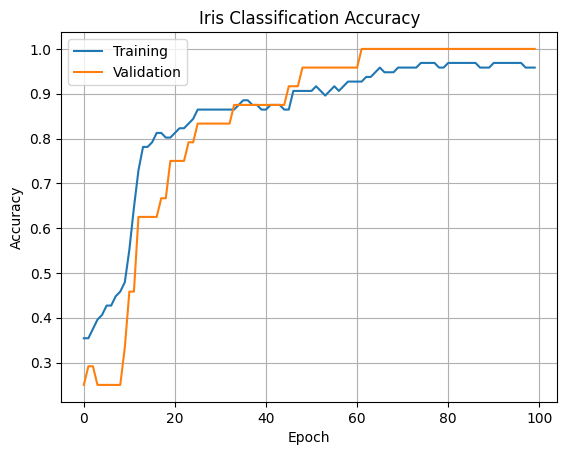

In [33]:
# ── Your Solution ──────────────────────────────────────────────
from sklearn.datasets import load_iris

# Hint: iris has 4 features, 3 output classes
# Use layers.Dense(3, activation='softmax') as final layer
# loss = 'sparse_categorical_crossentropy'

# TODO: Load Iris dataset
# TODO: Build Keras model (4 → 16 → 8 → 3 softmax)
# TODO: Compile and train
# TODO: Print classification report

# Load Iris dataset
iris = load_iris()

X_iris = iris.data.astype(np.float32)
y_iris = iris.target

# Split data
X_ir_train, X_ir_test, y_ir_train, y_ir_test = train_test_split(
    X_iris, y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

# Standardize data
iris_scaler = StandardScaler()

X_ir_train = iris_scaler.fit_transform(X_ir_train)
X_ir_test = iris_scaler.transform(X_ir_test)

# Build TensorFlow model
iris_model = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax")
])

# Compile
iris_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = iris_model.fit(
    X_ir_train,
    y_ir_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

# Predict
probabilities = iris_model.predict(X_ir_test, verbose=0)

predictions = np.argmax(probabilities, axis=1)

# Evaluation
from sklearn.metrics import accuracy_score
print("Test Accuracy:", accuracy_score(y_ir_test, predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_ir_test,
        predictions,
        labels=[0, 1, 2],
        target_names=iris.target_names,
        zero_division=0
    )
)

# Per-class accuracy
for class_id, class_name in enumerate(iris.target_names):
    mask = y_ir_test == class_id

    class_acc = np.mean(
        predictions[mask] == y_ir_test[mask]
    )

    print(f"{class_name} Accuracy: {class_acc:.4f}")

# Plot training
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Iris Classification Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

### 🎯 Task 5 — Custom Training Loop (TensorFlow)
Replicate the TensorFlow training loop manually using `tf.GradientTape` (no `.fit()`).  
Train on the cancer dataset, print loss every 10 epochs, and compare with the `.fit()` result.

In [39]:
# ── Your Solution ──────────────────────────────────────────────
# Hint structure:
# for epoch in range(EPOCHS):
#     with tf.GradientTape() as tape:
#         preds = model(X, training=True)
#         loss  = loss_fn(y, preds)
#     grads = tape.gradient(loss, model.trainable_variables)
#     optimizer.apply_gradients(zip(grads, model.trainable_variables))

# TODO: Build a fresh Keras model
# TODO: Implement the manual training loop above
# TODO: Print loss every 10 epochs
# TODO: Compute and print final test accuracy

# 1. Load dataset
data = load_breast_cancer()
X = data.data.astype("float32")
y = data.target.astype("float32")

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Normalize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

# 4. Build model
def build_tf_cancer():
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    return model

manual_model = build_tf_cancer()

# 5. Optimizer and loss
optimizer = keras.optimizers.Adam(learning_rate=0.001)
loss_fn = keras.losses.BinaryCrossentropy()

# 6. Create dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).shuffle(len(X_train), seed=42).batch(32)

# 7. Custom training loop using GradientTape
for epoch in range(50):
    epoch_losses = []

    for xb, yb in train_dataset:
        yb = tf.reshape(yb, (-1, 1))

        with tf.GradientTape() as tape:
            predictions = manual_model(xb, training=True)
            loss = loss_fn(yb, predictions)

        gradients = tape.gradient(
            loss, manual_model.trainable_variables
        )

        optimizer.apply_gradients(
            zip(gradients, manual_model.trainable_variables)
        )

        epoch_losses.append(float(loss.numpy()))

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/50 - "
            f"Loss: {np.mean(epoch_losses):.4f}"
        )

# 8. Evaluate manually trained model
test_predictions = manual_model(
    X_test, training=False
).numpy().flatten()

test_accuracy = np.mean(
    (test_predictions >= 0.5).astype(int) == y_test
)

print(f"\nManual Training Test Accuracy: {test_accuracy:.4f}")

# 9. Compare with Keras .fit()
keras_model = build_tf_cancer()
keras_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

keras_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    verbose=0
)

_, keras_accuracy = keras_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Keras .fit() Test Accuracy: {keras_accuracy:.4f}")
print(f"Accuracy Difference: {abs(test_accuracy - keras_accuracy):.4f}")

Epoch 10/50 - Loss: 0.0905
Epoch 20/50 - Loss: 0.0486
Epoch 30/50 - Loss: 0.0350
Epoch 40/50 - Loss: 0.0262
Epoch 50/50 - Loss: 0.0188

Manual Training Test Accuracy: 0.9561
Keras .fit() Test Accuracy: 0.9649
Accuracy Difference: 0.0088


### 🎯 Task 6 — Transfer Learning Preview (Bonus)
Freeze all layers of the TF cancer model except the last Dense layer.  
Retrain only the last layer for 20 more epochs. Compare with fine-tuning all layers.

In [41]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: layer.trainable = False / True
# After freezing layers, recompile the model!

# TODO: Print layer names of tf_cancer_model
# TODO: Freeze all layers except the last
# TODO: Recompile and retrain for 20 epochs
# TODO: Compare accuracy: frozen vs full fine-tune

# 1. Clone the previously trained model
frozen_model = keras.models.clone_model(tf_cancer_model)
frozen_model.set_weights(tf_cancer_model.get_weights())

print("Model Layers:")
for layer in frozen_model.layers:
    print(layer.name)

# 2. Freeze all layers except the final Dense layer
for layer in frozen_model.layers[:-1]:
    layer.trainable = False

frozen_model.layers[-1].trainable = True

# 3. Compile frozen model
frozen_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Train frozen model
frozen_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 5. Evaluate frozen model
_, frozen_acc = frozen_model.evaluate(
    X_test, y_test, verbose=0
)

# 6. Clone model for full fine-tuning
full_model = keras.models.clone_model(tf_cancer_model)
full_model.set_weights(tf_cancer_model.get_weights())

# Unfreeze all layers
for layer in full_model.layers:
    layer.trainable = True

# 7. Compile full model
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 8. Train full model
full_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 9. Evaluate full model
_, full_acc = full_model.evaluate(
    X_test, y_test, verbose=0
)

# 10. Compare results
print("\n========== RESULTS ==========")
print(f"Frozen Model Accuracy: {frozen_acc:.4f}")
print(f"Full Fine-Tuning Accuracy: {full_acc:.4f}")

print(f"Accuracy Difference: {abs(full_acc - frozen_acc):.4f}")

Model Layers:
dense_3
dropout
dense_4
dense_5

========== RESULTS ==========
Frozen Model Accuracy: 0.9737
Full Fine-Tuning Accuracy: 0.9737
Accuracy Difference: 0.0000


---
### 🎯 Task 7 — Tensor Broadcasting & Normalization
Given a matrix of shape `(5, 4)` with random values, normalize **each column** to have mean=0 and std=1 (z-score normalization) **without using sklearn** — use only PyTorch tensor operations.
Verify by printing the column-wise mean and std of the result (should be ≈0 and ≈1).

In [42]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: use .mean(dim=0) and .std(dim=0)
# Broadcasting will handle the subtraction/division automatically

torch.manual_seed(42)
M = torch.randn(5, 4) * 10 + 5   # raw data with mean≈5, std≈10
print("Original column means:", M.mean(dim=0).numpy().round(2))
print("Original column stds :", M.std(dim=0).numpy().round(2))

# TODO: compute M_norm so each column has mean≈0, std≈1
# TODO: verify

torch.manual_seed(42)

# Generate random matrix
M = torch.randn(5, 4) * 10 + 5

print("Original Matrix:")
print(M)

print("\nOriginal Column Means:")
print(M.mean(dim=0))

print("\nOriginal Column Standard Deviations:")
print(M.std(dim=0))

# Column-wise normalization
mean = M.mean(dim=0)
std = M.std(dim=0)

M_norm = (M - mean) / std

print("\nNormalized Matrix:")
print(M_norm)

# Verification
print("\nNormalized Column Means:")
print(M_norm.mean(dim=0))

print("\nNormalized Column Standard Deviations:")
print(M_norm.std(dim=0))

Original column means: [6.97 8.05 8.52 5.11]
Original column stds : [10.45  9.41  6.68 14.53]
Original Matrix:
tensor([[ 24.2692,  19.8728,  14.0072, -16.0552],
        [ -2.5813,  15.7832,  13.0080,  21.8062],
        [  8.5586,  -1.8662,   0.0664,   7.4149],
        [  2.6838,   5.4176,   2.4842,  13.5986],
        [  1.9027,   1.0429,  13.0341,  -1.2160]])

Original Column Means:
tensor([6.9666, 8.0501, 8.5200, 5.1097])

Original Column Standard Deviations:
tensor([10.4530,  9.4067,  6.6806, 14.5268])

Normalized Matrix:
tensor([[ 1.6553,  1.2569,  0.8214, -1.4570],
        [-0.9134,  0.8221,  0.6718,  1.1494],
        [ 0.1523, -1.0542, -1.2654,  0.1587],
        [-0.4097, -0.2799, -0.9035,  0.5844],
        [-0.4844, -0.7449,  0.6757, -0.4354]])

Normalized Column Means:
tensor([-1.7881e-08,  3.5763e-08,  1.1921e-08,  5.9605e-09])

Normalized Column Standard Deviations:
tensor([1.0000, 1.0000, 1.0000, 1.0000])


### 🎯 Task 8 — Implement a Custom Loss Function
Implement **Huber Loss** from scratch in both PyTorch and TensorFlow (no built-ins).  
Huber loss is less sensitive to outliers than MSE:
$$L_{\delta}(y, \hat{y}) = \begin{cases} \frac{1}{2}(y-\hat{y})^2 & \text{if } |y-\hat{y}| \le \delta \\ \delta \cdot |y-\hat{y}| - \frac{\delta^2}{2} & \text{otherwise} \end{cases}$$
Test it with some sample predictions and compare against PyTorch's built-in `HuberLoss`.

In [43]:
# ── Your Solution ──────────────────────────────────────────────
# Hint (PyTorch):  use torch.where(condition, x, y)
# Hint (TF):       use tf.where(condition, x, y)

y_true_sample = torch.tensor([1.0, 2.0, 3.0, 4.0, 100.0])  # note the outlier!
y_pred_sample = torch.tensor([1.1, 2.5, 2.8, 4.2,   5.0])

# TODO: implement huber_loss_pt(y_true, y_pred, delta=1.0) in PyTorch
# TODO: implement huber_loss_tf(y_true, y_pred, delta=1.0) in TensorFlow
# TODO: compare both with nn.HuberLoss()

# Sample data
y_true_sample = torch.tensor([1.0, 2.0, 3.0, 4.0, 100.0])
y_pred_sample = torch.tensor([1.1, 2.5, 2.8, 4.2, 5.0])

# Custom PyTorch Huber Loss
def huber_loss_pt(y_true, y_pred, delta=1.0):

    error = torch.abs(y_true - y_pred)

    loss = torch.where(
        error <= delta,
        0.5 * error**2,
        delta * error - 0.5 * delta**2
    )

    return loss.mean()


# Custom TensorFlow Huber Loss
def huber_loss_tf(y_true, y_pred, delta=1.0):

    error = tf.abs(y_true - y_pred)

    loss = tf.where(
        error <= delta,
        0.5 * tf.square(error),
        delta * error - 0.5 * delta**2
    )

    return tf.reduce_mean(loss)


# PyTorch custom loss
pt_loss = huber_loss_pt(
    y_true_sample, y_pred_sample
)

# TensorFlow custom loss
tf_loss = huber_loss_tf(
    tf.constant(y_true_sample.numpy()),
    tf.constant(y_pred_sample.numpy())
)

# Built-in PyTorch Huber Loss
built_in_loss = nn.HuberLoss(delta=1.0)

builtin_result = built_in_loss(
    y_pred_sample, y_true_sample
)

print("Custom PyTorch Huber Loss:", pt_loss.item())
print("Custom TensorFlow Huber Loss:", tf_loss.numpy())
print("Built-in PyTorch Huber Loss:", builtin_result.item())

# Compare with MSE
mse = nn.MSELoss()(y_pred_sample, y_true_sample)

print("MSE Loss:", mse.item())

Custom PyTorch Huber Loss: 18.933998107910156
Custom TensorFlow Huber Loss: 18.934
Built-in PyTorch Huber Loss: 18.933998107910156
MSE Loss: 1805.0679931640625


### 🎯 Task 9 — Learning Rate Comparison
Train three identical PyTorch models on the cancer dataset using **different learning rates**: `0.1`, `0.001`, `0.00001`.  
Plot all three loss curves on the same chart and explain which learning rate works best and why.

In [45]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: write a helper function  train_model(lr, epochs=60)
# that returns a list of losses, then plot all 3 on one figure

# TODO: define train_model(lr, epochs)
# TODO: run for lr in [0.1, 0.001, 0.00001]
# TODO: plot all curves and explain the result

# 1. Clone the previously trained model
frozen_model = keras.models.clone_model(tf_cancer_model)
frozen_model.set_weights(tf_cancer_model.get_weights())

print("Model Layers:")
for layer in frozen_model.layers:
    print(layer.name)

# 2. Freeze all layers except the final Dense layer
for layer in frozen_model.layers[:-1]:
    layer.trainable = False

frozen_model.layers[-1].trainable = True

# 3. Compile frozen model
frozen_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Train frozen model
frozen_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 5. Evaluate frozen model
_, frozen_acc = frozen_model.evaluate(
    X_test, y_test, verbose=0
)

# 6. Clone model for full fine-tuning
full_model = keras.models.clone_model(tf_cancer_model)
full_model.set_weights(tf_cancer_model.get_weights())

# Unfreeze all layers
for layer in full_model.layers:
    layer.trainable = True

# 7. Compile full model
full_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 8. Train full model
full_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# 9. Evaluate full model
_, full_acc = full_model.evaluate(
    X_test, y_test, verbose=0
)

# 10. Compare results
print("\n========== RESULTS ==========")
print(f"Frozen Model Accuracy: {frozen_acc:.4f}")
print(f"Full Fine-Tuning Accuracy: {full_acc:.4f}")

print(f"Accuracy Difference: {abs(full_acc - frozen_acc):.4f}")

Model Layers:
dense_3
dropout
dense_4
dense_5

========== RESULTS ==========
Frozen Model Accuracy: 0.9737
Full Fine-Tuning Accuracy: 0.9737
Accuracy Difference: 0.0000


### 🎯 Task 10 — Dropout Regularization Experiment
Train two TensorFlow models on a **small noisy dataset** (200 samples):  
- **Model A**: no Dropout  
- **Model B**: with `Dropout(0.4)` after each hidden layer  

Plot train vs validation accuracy for both and explain which overfits more.

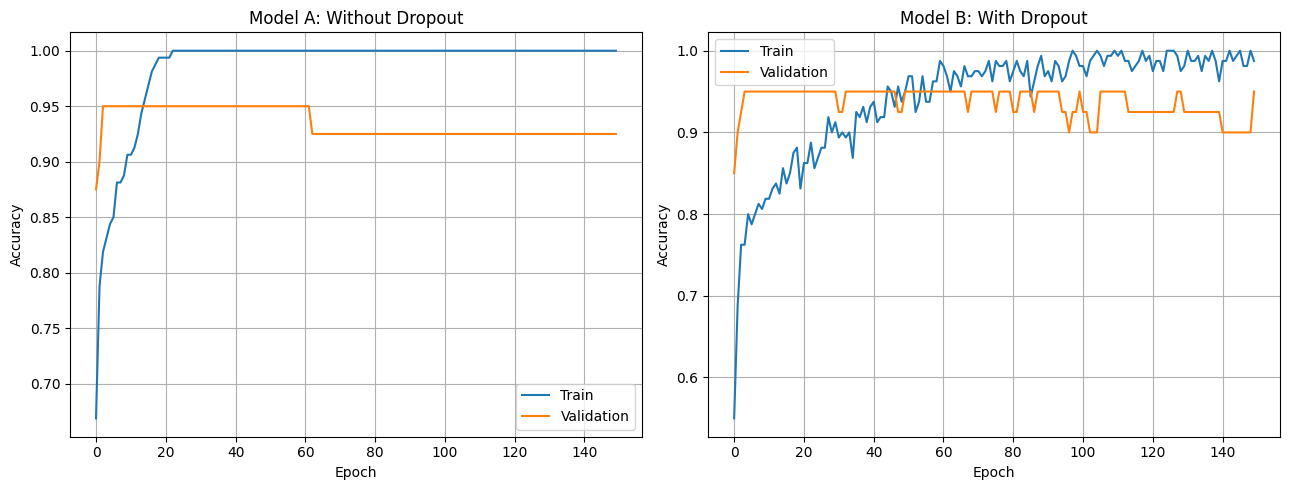


========== RESULTS ==========
Without Dropout: Train=1.0000, Validation=0.9250, Gap=0.0750
With Dropout: Train=0.9875, Validation=0.9500, Gap=0.0375


In [47]:
# ── Your Solution ──────────────────────────────────────────────
# Use only 200 samples from breast cancer to force overfitting
# Model A: Dense → Dense → Output  (no dropout)
# Model B: Dense → Dropout → Dense → Dropout → Output

# TODO: slice 200 samples from X_train, y_train
# TODO: build and train Model A (no dropout)
# TODO: build and train Model B (with dropout)
# TODO: plot train vs val accuracy side by side

# 1. Select 200 samples from training data
indices = np.arange(len(X_train))

selected, _ = train_test_split(
    indices,
    train_size=200,
    random_state=42,
    stratify=y_train
)

X_small = X_train[selected]
y_small = y_train[selected]

# 2. Split into training and validation
X_s_train, X_s_val, y_s_train, y_s_val = train_test_split(
    X_small,
    y_small,
    test_size=0.2,
    random_state=42,
    stratify=y_small
)

# 3. Add noise to training data
rng = np.random.default_rng(42)

X_s_train = X_s_train + rng.normal(
    0, 0.5, X_s_train.shape
).astype(np.float32)

# Flip 15% of training labels
y_s_train = y_s_train.copy()

noise_indices = rng.choice(
    len(y_s_train),
    size=int(0.15 * len(y_s_train)),
    replace=False
)

y_s_train[noise_indices] = 1 - y_s_train[noise_indices]


# 4. Model building function
def build_dropout_model(use_dropout=False):

    model_layers = [
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation="relu")
    ]

    if use_dropout:
        model_layers.append(layers.Dropout(0.4))

    model_layers.append(
        layers.Dense(64, activation="relu")
    )

    if use_dropout:
        model_layers.append(layers.Dropout(0.4))

    model_layers.append(
        layers.Dense(1, activation="sigmoid")
    )

    model = keras.Sequential(model_layers)

    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 5. Model A: Without Dropout
keras.utils.set_random_seed(42)

model_A = build_dropout_model(False)

history_A = model_A.fit(
    X_s_train,
    y_s_train,
    validation_data=(X_s_val, y_s_val),
    epochs=150,
    batch_size=16,
    verbose=0
)


# 6. Model B: With Dropout
keras.utils.set_random_seed(42)

model_B = build_dropout_model(True)

history_B = model_B.fit(
    X_s_train,
    y_s_train,
    validation_data=(X_s_val, y_s_val),
    epochs=150,
    batch_size=16,
    verbose=0
)


# 7. Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history_A.history["accuracy"],
    label="Train"
)
axes[0].plot(
    history_A.history["val_accuracy"],
    label="Validation"
)
axes[0].set_title("Model A: Without Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    history_B.history["accuracy"],
    label="Train"
)
axes[1].plot(
    history_B.history["val_accuracy"],
    label="Validation"
)
axes[1].set_title("Model B: With Dropout")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# 8. Compare final accuracy
print("\n========== RESULTS ==========")

for name, history in [
    ("Without Dropout", history_A),
    ("With Dropout", history_B)
]:
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]

    print(
        f"{name}: Train={train_acc:.4f}, "
        f"Validation={val_acc:.4f}, "
        f"Gap={train_acc - val_acc:.4f}"
    )

### 🎯 Task 11 — Optimizer Comparison (Adam vs SGD vs RMSprop)
Train the same network architecture with three different optimizers in TensorFlow.  
Plot convergence speed and final validation accuracy to understand trade-offs.

Adam: Best Validation Accuracy = 1.0000, Test Accuracy = 0.9561
SGD: Best Validation Accuracy = 0.9890, Test Accuracy = 0.9649
RMSprop: Best Validation Accuracy = 0.9890, Test Accuracy = 0.9737


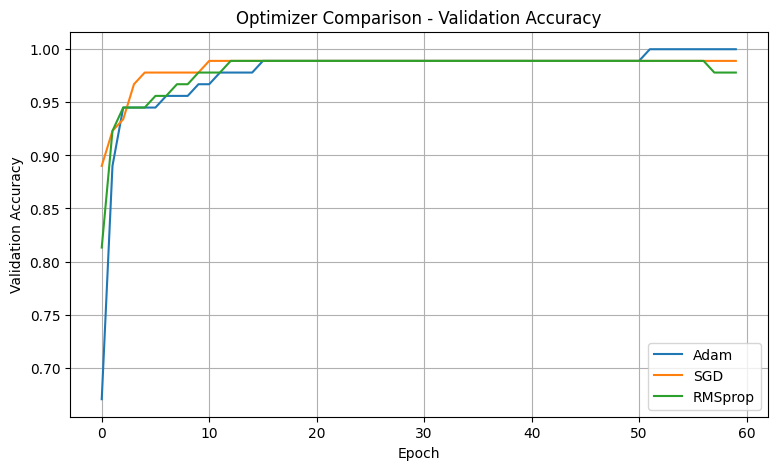

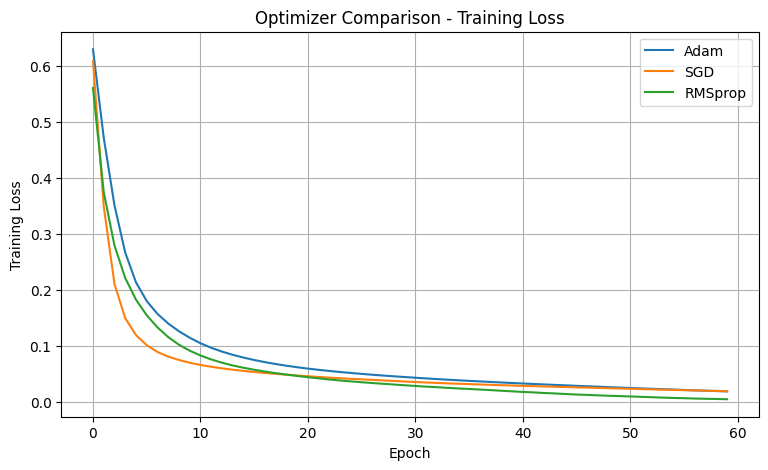


========== OPTIMIZER COMPARISON ==========
Adam: Validation Accuracy = 1.0000, Test Accuracy = 0.9561
SGD: Validation Accuracy = 0.9890, Test Accuracy = 0.9649
RMSprop: Validation Accuracy = 0.9890, Test Accuracy = 0.9737

Best Optimizer (Validation Accuracy): Adam


In [49]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: keras.optimizers.SGD(lr, momentum=0.9)
#       keras.optimizers.Adam(lr)
#       keras.optimizers.RMSprop(lr)

# TODO: create a helper build_and_train(optimizer_name, lr, epochs)
# TODO: run for all 3 optimizers
# TODO: plot val_accuracy curves on a single chart

# 1. Model training function
def build_and_train(optimizer_name, lr, epochs=60):

    keras.utils.set_random_seed(42)

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    # 2. Select optimizer
    if optimizer_name == "Adam":
        optimizer = keras.optimizers.Adam(
            learning_rate=lr
        )

    elif optimizer_name == "SGD":
        optimizer = keras.optimizers.SGD(
            learning_rate=lr,
            momentum=0.9
        )

    elif optimizer_name == "RMSprop":
        optimizer = keras.optimizers.RMSprop(
            learning_rate=lr
        )

    else:
        raise ValueError("Unknown optimizer")

    # 3. Compile model
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    # 4. Train model
    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=32,
        verbose=0
    )

    return model, history


# 5. Optimizer settings
optimizer_settings = {
    "Adam": 0.001,
    "SGD": 0.01,
    "RMSprop": 0.001
}

optimizer_histories = {}
optimizer_results = {}

# 6. Train and evaluate each optimizer
for name, lr in optimizer_settings.items():

    model, history = build_and_train(
        name, lr, epochs=60
    )

    optimizer_histories[name] = history

    # Evaluate on test dataset
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    optimizer_results[name] = {
        "Validation Accuracy": max(history.history["val_accuracy"]),
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss
    }

    print(
        f"{name}: "
        f"Best Validation Accuracy = "
        f"{max(history.history['val_accuracy']):.4f}, "
        f"Test Accuracy = {test_accuracy:.4f}"
    )


# 7. Plot validation accuracy
plt.figure(figsize=(9, 5))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.title("Optimizer Comparison - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 8. Plot training loss
plt.figure(figsize=(9, 5))

for name, history in optimizer_histories.items():
    plt.plot(
        history.history["loss"],
        label=name
    )

plt.title("Optimizer Comparison - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.legend()
plt.grid(True)
plt.show()


# 9. Print final comparison
print("\n========== OPTIMIZER COMPARISON ==========")

for name, result in optimizer_results.items():
    print(
        f"{name}: "
        f"Validation Accuracy = {result['Validation Accuracy']:.4f}, "
        f"Test Accuracy = {result['Test Accuracy']:.4f}"
    )

# Select best optimizer using validation accuracy
best_optimizer = max(
    optimizer_results,
    key=lambda name: optimizer_results[name]["Validation Accuracy"]
)

print("\nBest Optimizer (Validation Accuracy):", best_optimizer)

### 🎯 Task 12 — Build a Network from Scratch (No Sequential)
Using PyTorch's `nn.Module`, build a **two-branch network** that:  
- Takes a single input `x` of shape `(N, 10)`
- Branch A: `Linear(10→16) → ReLU → Linear(16→8)`
- Branch B: `Linear(10→8)  → Tanh`
- Merges branches by **adding** them element-wise
- Final head: `Linear(8→1) → Sigmoid`

Run a forward pass and print the output shape.

In [50]:
# ── Your Solution ──────────────────────────────────────────────
# You CANNOT use nn.Sequential here — use nn.Module with a custom forward()

class TwoBranchNet(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: define branch_a layers
        # TODO: define branch_b layers
        # TODO: define final head
        pass

    def forward(self, x):
        # TODO: forward through branch_a
        # TODO: forward through branch_b
        # TODO: add branches, pass through head
        pass

# TODO: instantiate and run dummy input of shape (8, 10)

class TwoBranchNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Branch A
        self.a1 = nn.Linear(10, 16)
        self.a2 = nn.Linear(16, 8)

        # Branch B
        self.b1 = nn.Linear(10, 8)

        # Final output layer
        self.output = nn.Linear(8, 1)

    def forward(self, x):

        # Branch A
        a = torch.relu(self.a1(x))
        a = self.a2(a)

        # Branch B
        b = torch.tanh(self.b1(x))

        # Merge branches
        merged = a + b

        # Final prediction
        output = torch.sigmoid(self.output(merged))

        return output


# Create model
model = TwoBranchNet()

print("Model Architecture:")
print(model)

# Dummy input
x = torch.randn(8, 10)

# Forward pass
output = model(x)

print("\nInput Shape:", x.shape)
print("Output Shape:", output.shape)

print("\nPredictions:")
print(output.detach())

Model Architecture:
TwoBranchNet(
  (a1): Linear(in_features=10, out_features=16, bias=True)
  (a2): Linear(in_features=16, out_features=8, bias=True)
  (b1): Linear(in_features=10, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
)

Input Shape: torch.Size([8, 10])
Output Shape: torch.Size([8, 1])

Predictions:
tensor([[0.6269],
        [0.5387],
        [0.5804],
        [0.6161],
        [0.5889],
        [0.6181],
        [0.5633],
        [0.5971]])


### 🎯 Task 13 — Early Stopping with Keras Callback
Train a TensorFlow model on the cancer dataset but use **Early Stopping** to automatically stop training when validation loss stops improving.  
Also add **Model Checkpoint** to save the best weights automatically.  
Print how many epochs actually ran vs the maximum.

Maximum Epochs: 200
Actual Epochs: 86
Test Accuracy: 0.9474
Best Validation Loss: 0.0248


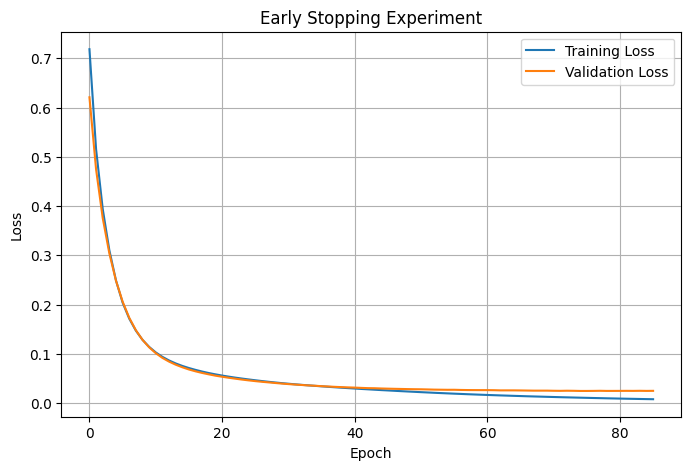


Best model saved at:
saved_models/best_model.keras


In [52]:
# ── Your Solution ──────────────────────────────────────────────
# Hint:
# early_stop = keras.callbacks.EarlyStopping(
#     monitor='val_loss', patience=10, restore_best_weights=True
# )
# checkpoint = keras.callbacks.ModelCheckpoint(
#     'saved_models/best_model.keras', save_best_only=True
# )
# model.fit(..., callbacks=[early_stop, checkpoint], epochs=200)

# TODO: implement above
# TODO: print actual epochs run vs max epochs

# 1. Create directory for saving model
os.makedirs("saved_models", exist_ok=True)

# 2. Build model
early_model = build_tf_cancer()

# 3. Compile model (required before training)
early_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Early stopping callback
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# 5. Model checkpoint callback
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="saved_models/best_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=0
)

# 6. Train model
history = early_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stop, checkpoint],
    verbose=0
)

# 7. Actual epochs used
actual_epochs = len(history.history["loss"])

print("Maximum Epochs:", 200)
print("Actual Epochs:", actual_epochs)

# 8. Evaluate model
test_loss, test_accuracy = early_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")

print(
    f"Best Validation Loss: "
    f"{min(history.history['val_loss']):.4f}"
)

# 9. Plot training curves
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Early Stopping Experiment")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

print("\nBest model saved at:")
print("saved_models/best_model.keras")

### 🎯 Task 14 — Batch Normalization Effect
Compare training stability **with and without Batch Normalization** in PyTorch.  
Use a deeper network (5 hidden layers). Train both for 80 epochs on the cancer dataset.  
Plot the gradient norms of the first layer across epochs to show vanishing gradient behavior.

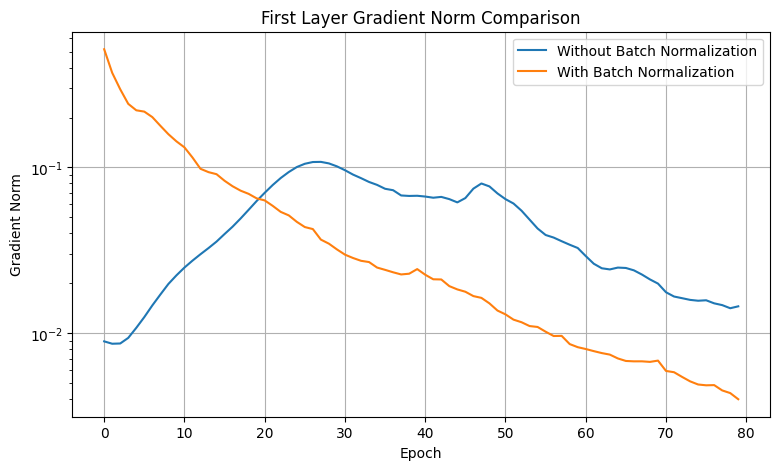

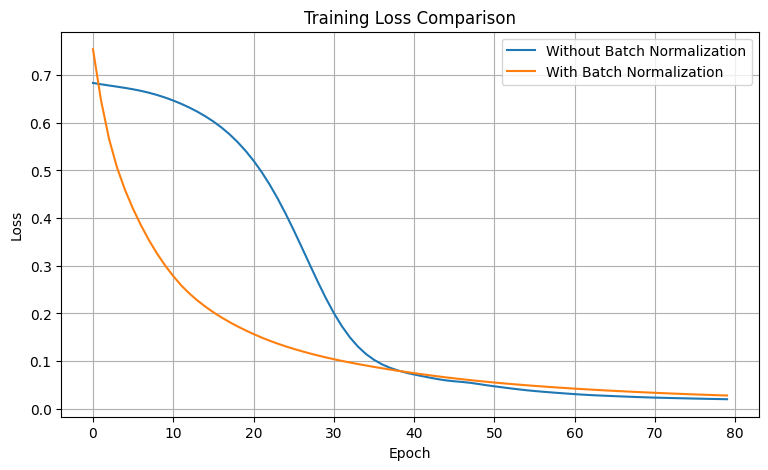


========== RESULTS ==========
Final Loss Without BN: 0.0202
Final Loss With BN: 0.0279
Final Gradient Norm Without BN: 0.0145
Final Gradient Norm With BN: 0.0040


In [57]:
# ── Your Solution ──────────────────────────────────────────────
# Hint: nn.BatchNorm1d(num_features) goes AFTER Linear, BEFORE activation
# To capture gradient norms:
#   after loss.backward(), read model.layer.weight.grad.norm().item()

# TODO: build DeepNetNoBN  (5 hidden layers, no batch norm)
# TODO: build DeepNetBN    (5 hidden layers, with BatchNorm1d)
# TODO: train both, record first-layer gradient norms each epoch
# TODO: plot gradient norms for both models

# 1. Convert training data into tensors
X_bn = torch.tensor(X_train, dtype=torch.float32)

y_bn = torch.tensor(
    y_train, dtype=torch.float32
).view(-1, 1)


# 2. Define deep neural network
class DeepNet(nn.Module):

    def __init__(self, use_bn=False):
        super().__init__()

        self.use_bn = use_bn

        # Five hidden layers
        self.hidden = nn.ModuleList()
        self.bn_layers = nn.ModuleList()

        input_size = X_train.shape[1]

        for i in range(5):

            self.hidden.append(
                nn.Linear(input_size, 64)
            )

            if use_bn:
                self.bn_layers.append(
                    nn.BatchNorm1d(64)
                )

            input_size = 64

        self.output = nn.Linear(64, 1)

    def forward(self, x):

        for i, layer in enumerate(self.hidden):

            x = layer(x)

            if self.use_bn:
                x = self.bn_layers[i](x)

            x = torch.relu(x)

        x = torch.sigmoid(self.output(x))

        return x


# 3. Training function
def train_deep_model(use_bn, epochs=80):

    torch.manual_seed(42)

    model = DeepNet(use_bn=use_bn)

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.BCELoss()

    gradient_norms = []
    losses = []

    for epoch in range(epochs):

        model.train()
        optimizer.zero_grad()

        predictions = model(X_bn)

        loss = criterion(predictions, y_bn)

        loss.backward()

        # First layer gradient norm
        grad_norm = (
            model.hidden[0].weight.grad.norm().item()
        )

        gradient_norms.append(grad_norm)
        losses.append(loss.item())

        optimizer.step()

    return model, gradient_norms, losses


# 4. Train both models
model_no_bn, grads_no_bn, losses_no_bn = train_deep_model(
    use_bn=False
)

model_bn, grads_bn, losses_bn = train_deep_model(
    use_bn=True
)


# 5. Plot gradient norms
plt.figure(figsize=(9, 5))

plt.plot(
    grads_no_bn,
    label="Without Batch Normalization"
)

plt.plot(
    grads_bn,
    label="With Batch Normalization"
)

plt.title("First Layer Gradient Norm Comparison")
plt.xlabel("Epoch")
plt.ylabel("Gradient Norm")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()


# 6. Plot training losses
plt.figure(figsize=(9, 5))

plt.plot(
    losses_no_bn,
    label="Without Batch Normalization"
)

plt.plot(
    losses_bn,
    label="With Batch Normalization"
)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# 7. Print results
print("\n========== RESULTS ==========")

print(f"Final Loss Without BN: {losses_no_bn[-1]:.4f}")
print(f"Final Loss With BN: {losses_bn[-1]:.4f}")

print(f"Final Gradient Norm Without BN: {grads_no_bn[-1]:.4f}")
print(f"Final Gradient Norm With BN: {grads_bn[-1]:.4f}")

### 🎯 Task 15 — End-to-End Mini Project (Both Frameworks)
**Diabetes Progression Prediction** — a full pipeline from scratch using sklearn's built-in diabetes dataset:
1. Load the Diabetes dataset (442 patients, 10 medical features)
2. Preprocess: scale features, binarize labels (progression above median → high risk)
3. Train **both** a PyTorch model and a TensorFlow model
4. Compare: Accuracy, Precision, Recall, F1, AUC
5. Print a final side-by-side summary table and visualise results

Dataset Shape: (442, 10)
Median Progression: 140.5
Class Distribution: [221 221]
PyTorch Epoch 30/150, Loss: 0.5477
PyTorch Epoch 60/150, Loss: 0.4696
PyTorch Epoch 90/150, Loss: 0.4365
PyTorch Epoch 120/150, Loss: 0.4101
PyTorch Epoch 150/150, Loss: 0.3833

========== FINAL MODEL COMPARISON ==========

           PyTorch  TensorFlow
Accuracy    0.7640      0.6966
Precision   0.7347      0.6735
Recall      0.8182      0.7500
F1          0.7742      0.7097
AUC         0.8293      0.8086

PyTorch Classification Report:
                  precision    recall  f1-score   support

 Low Progression       0.80      0.71      0.75        45
High Progression       0.73      0.82      0.77        44

        accuracy                           0.76        89
       macro avg       0.77      0.76      0.76        89
    weighted avg       0.77      0.76      0.76        89


TensorFlow Classification Report:
                  precision    recall  f1-score   support

 Low Progression       0.72     

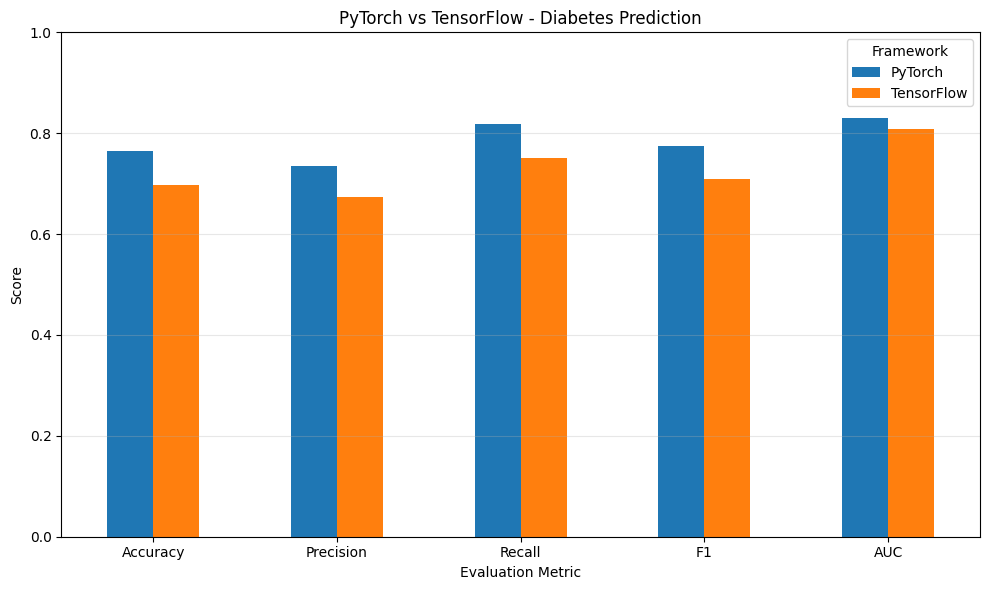

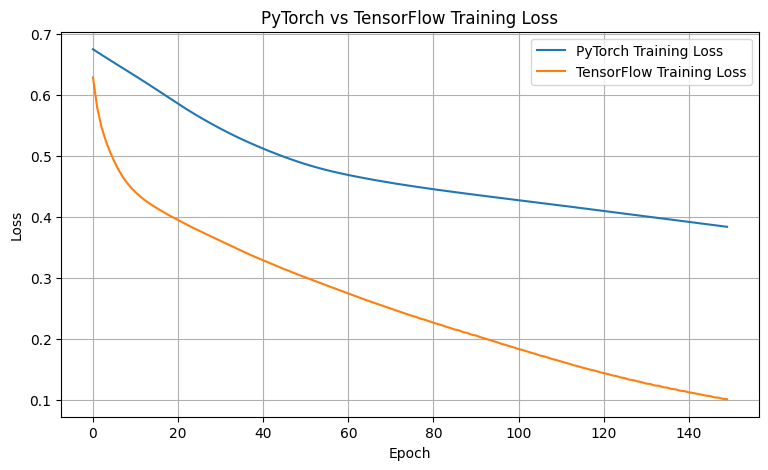


========== FINAL SUMMARY ==========
PyTorch Accuracy: 0.7640
TensorFlow Accuracy: 0.6966
PyTorch has the higher F1 score.


In [62]:
# ── Your Solution ──────────────────────────────────────────────
from sklearn.datasets import load_diabetes

# Load hint:
#   diab = load_diabetes()
#   X_d, y_d = diab.data, diab.target
#   Binarize: y_d = (y_d > np.median(y_d)).astype(np.float32)

# TODO: load, binarize, split, scale
# TODO: train PyTorch model  (10 → 64 → 32 → 1)
# TODO: train TensorFlow model
# TODO: print comparison table with all 5 metrics

# ============================================================
# 1. Load Diabetes Dataset
# ============================================================
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, accuracy_score
import pandas as pd

diabetes = load_diabetes()

X_d = diabetes.data.astype(np.float32)
y_original = diabetes.target

print("Dataset Shape:", X_d.shape)

# Binarize target using median progression
median_progression = np.median(y_original)

y_d = (
    y_original > median_progression
).astype(np.float32)

print("Median Progression:", median_progression)
print("Class Distribution:", np.bincount(y_d.astype(int)))


# ============================================================
# 2. Train-Test Split
# ============================================================

X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(
    X_d,
    y_d,
    test_size=0.2,
    random_state=42,
    stratify=y_d
)

# Feature scaling
scaler_d = StandardScaler()

X_d_train = scaler_d.fit_transform(
    X_d_train
).astype(np.float32)

X_d_test = scaler_d.transform(
    X_d_test
).astype(np.float32)


# ============================================================
# 3. PyTorch Model
# ============================================================

class DiabetesNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(10, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(42)

pt_diabetes = DiabetesNet()

# Convert data to tensors
X_d_train_pt = torch.tensor(X_d_train)

y_d_train_pt = torch.tensor(
    y_d_train
).view(-1, 1)

X_d_test_pt = torch.tensor(X_d_test)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    pt_diabetes.parameters(),
    lr=0.001
)

# Train PyTorch model
pt_losses = []

for epoch in range(150):

    pt_diabetes.train()

    optimizer.zero_grad()

    logits = pt_diabetes(X_d_train_pt)

    loss = criterion(logits, y_d_train_pt)

    loss.backward()
    optimizer.step()

    pt_losses.append(loss.item())

    if (epoch + 1) % 30 == 0:
        print(
            f"PyTorch Epoch {epoch+1}/150, "
            f"Loss: {loss.item():.4f}"
        )


# PyTorch predictions
pt_diabetes.eval()

with torch.no_grad():

    pt_logits = pt_diabetes(X_d_test_pt)

    pt_probabilities = torch.sigmoid(
        pt_logits
    ).numpy().flatten()

pt_predictions = (
    pt_probabilities >= 0.5
).astype(int)


# ============================================================
# 4. TensorFlow Model
# ============================================================

tf.random.set_seed(42)

tf_diabetes = keras.Sequential([
    layers.Input(shape=(10,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Compile
tf_diabetes.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train TensorFlow model
tf_diabetes_history = tf_diabetes.fit(
    X_d_train,
    y_d_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# TensorFlow predictions
tf_probabilities = tf_diabetes.predict(
    X_d_test,
    verbose=0
).flatten()

tf_predictions = (
    tf_probabilities >= 0.5
).astype(int)


# ============================================================
# 5. Evaluation Function
# ============================================================

def calculate_metrics(y_true, y_pred, y_prob):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "AUC": roc_auc_score(
            y_true, y_prob
        )
    }


# Calculate metrics
pt_metrics = calculate_metrics(
    y_d_test,
    pt_predictions,
    pt_probabilities
)

tf_metrics = calculate_metrics(
    y_d_test,
    tf_predictions,
    tf_probabilities
)


# ============================================================
# 6. Comparison Table
# ============================================================

comparison = pd.DataFrame({
    "PyTorch": pt_metrics,
    "TensorFlow": tf_metrics
})

print("\n========== FINAL MODEL COMPARISON ==========\n")

print(comparison.round(4).to_string())


# ============================================================
# 7. Classification Reports
# ============================================================

print("\nPyTorch Classification Report:")

print(
    classification_report(
        y_d_test,
        pt_predictions,
        target_names=["Low Progression", "High Progression"],
        zero_division=0
    )
)

print("\nTensorFlow Classification Report:")

print(
    classification_report(
        y_d_test,
        tf_predictions,
        target_names=["Low Progression", "High Progression"],
        zero_division=0
    )
)


# ============================================================
# 8. Visualize Performance
# ============================================================

comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("PyTorch vs TensorFlow - Diabetes Prediction")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Framework")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 9. Training Loss Comparison
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    pt_losses,
    label="PyTorch Training Loss"
)

plt.plot(
    tf_diabetes_history.history["loss"],
    label="TensorFlow Training Loss"
)

plt.title("PyTorch vs TensorFlow Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 10. Final Summary
# ============================================================

print("\n========== FINAL SUMMARY ==========")

print(
    f"PyTorch Accuracy: "
    f"{pt_metrics['Accuracy']:.4f}"
)

print(
    f"TensorFlow Accuracy: "
    f"{tf_metrics['Accuracy']:.4f}"
)

if pt_metrics["F1"] > tf_metrics["F1"]:
    print("PyTorch has the higher F1 score.")

elif tf_metrics["F1"] > pt_metrics["F1"]:
    print("TensorFlow has the higher F1 score.")

else:
    print("Both models have equal F1 scores.")

---
## 🎓 Summary — Key Concepts Covered

| Concept | PyTorch | TensorFlow |
|---------|---------|------------|
| Create tensor | `torch.tensor()`, `torch.rand()` | `tf.constant()`, `tf.random.uniform()` |
| Track gradients | `requires_grad=True` + `.backward()` | `tf.GradientTape()` |
| Define model | `class Net(nn.Module)` | `keras.Sequential([...])` |
| Loss function | `nn.BCELoss()`, `nn.MSELoss()` | `'binary_crossentropy'`, `'mse'` |
| Optimizer | `optim.Adam(params, lr=...)` | `keras.optimizers.Adam(lr=...)` |
| Training | Manual loop + `.backward()` | `.fit(X, y, epochs=...)` |
| Evaluate | Manual with `torch.no_grad()` | `.evaluate(X_test, y_test)` |
| Save model | `torch.save(state_dict)` | `model.save(path)` |
| Load model | `model.load_state_dict(torch.load(...))` | `keras.models.load_model(path)` |

### 📚 Next Steps
- **Convolutional Neural Networks (CNNs)** — for image data
- **Recurrent Neural Networks (RNNs / LSTMs)** — for sequences/text
- **Transfer Learning** — using pre-trained models (ResNet, BERT)
- **PyTorch Lightning** — structured PyTorch training
- **Keras Functional API** — complex multi-input/output architectures

---
*Happy Learning! 🚀*